# Apophis, 2004: the 1.4 arcseconds that moved the 2029 flyby

**The story.** (99942) Apophis was discovered on 19 June 2004 at Kitt Peak, lost after two nights,
and recovered in December 2004. By 27 December the December astrometry gave a 2.7% chance of an
Earth impact on 13 April 2029, the highest ever recorded, until precovery images from Spacewatch
(station 691) taken on 15 March 2004 were found and measured that same evening: the longer arc
ruled the impact out. Then the first Arecibo radar echo, in January 2005, landed 4.8σ from the
prediction and "revealed a previously undetected 1.4 arcsec systematic bias in the pre-discovery
optical measurements" (Giorgini et al. 2008, Icarus 193, 1). The six March 2004 images were
remeasured independently by two people, and the corrected solution moved the 2029 encounter
28,000 km *closer* to Earth, a 5σ change. A second remeasurement campaign followed in 2009:
Tholen, Micheli and Elliott (2013, Acta Astronautica 90, 56) re-reduced more than 430 of their
2004-2008 positions against the 2MASS catalogue, and the 2036 impact chance fell from 1 in 45,000
to 4 in a million.

**The question.** Can we reproduce the first remeasurement from the public record? The
*original* March 2004 positions are printed in
[MPEC 2004-Y70](https://www.minorplanetcenter.net/mpec/K04/K04Y70.html); the MPC database now
serves the *remeasured* ones (reference MPC 53585). We fit the astrometry as it stood at the end
of 2004 three ways: without the March precovery, with the original March positions, and with the
remeasured ones, and predict the 2029 pass from each. The published yardsticks: 48.6 ± 7.0 Earth
radii from the June-December 2004 arc alone and 5.54 ± 0.48 with the (remeasured) March data
(Królikowska et al. 2009, MNRAS 399, 1964); 10.2 Earth radii with the original March positions
and 5.96 ± 0.08 after the radar (Giorgini et al. 2008); 38,012 km = 5.96 Earth radii today
(notebook 02).

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pyroorb

pyroorb.load_settings()       # the .env settings file (data folders), before the first fit
pyroorb.asteroid_perturbers() # the 16 most massive asteroids, as JPL uses for Apophis (notebook 02)

# Future UTC dates make astropy warn that leap seconds are not yet known; harmless here.
warnings.filterwarnings("ignore", message=".*dubious year.*")
plt.rcParams.update({"figure.figsize": (8, 4.5), "figure.dpi": 110, "axes.grid": True,
                     "grid.alpha": 0.3})
print("PyRoOrb", pyroorb.__version__)

PyRoOrb 0.9.0


## 1. The two versions of 15 March 2004

The five original lines, copied from MPEC 2004-Y70 (80-column MPC format; `read_observations`
parses them), and the five remeasured ones the MPC serves today. Spacewatch measured a sixth image
later (reference MPS 126394); it has no original and is left out of both sets.

In [2]:
import tempfile
from astropy.time import Time

MPEC_2004_Y70 = '''\
     K04M04N tC2004 03 15.11040 04 06 08.68 +16 55 06.0                 EY070691
     K04M04N tC2004 03 15.12365 04 06 11.86 +16 55 16.0                 EY070691
     K04M04N tC2004 03 15.12629 04 06 12.50 +16 55 17.5                 EY070691
     K04M04N tC2004 03 15.13723 04 06 14.99 +16 55 25.2                 EY070691
     K04M04N tC2004 03 15.13998 04 06 15.67 +16 55 27.1                 EY070691
'''
with tempfile.NamedTemporaryFile("w", suffix=".obs", delete=False) as fh:
    fh.write(MPEC_2004_Y70)
original = list(pyroorb.read_observations(fh.name))

obs = pyroorb.fetch_observations("99942")
end2004 = Time("2005-01-01").jd
march_now = sorted((o for o in obs if o["obscode"] == "691" and o["jd_utc"] < end2004), key=lambda o: o["jd_utc"])
remeasured = [o for o in march_now if str(o.get("ref", "")).strip() == "MPC    53585"]
rest2004 = [o for o in obs if o["jd_utc"] < end2004 and o not in march_now]
original = [{**o, "designation": remeasured[0]["designation"]} for o in original]   # same object

rows = []
for o_orig, o_new in zip(original, remeasured):
    cosd = np.cos(np.radians(o_new["dec_deg"]))
    rows.append({"UTC": Time(o_new["jd_utc"], format="jd").iso[:19],
                 "dRA remeasured - original (arcsec)": round((o_new["ra_deg"] - o_orig["ra_deg"]) * 3600 * cosd, 2),
                 "dDec (arcsec)": round((o_new["dec_deg"] - o_orig["dec_deg"]) * 3600, 2),
                 "dt (s)": round((o_new["jd_utc"] - o_orig["jd_utc"]) * 86400, 1)})
print(f"{len(rest2004)} other optical observations in 2004 (19 June - 31 December), radar from "
      f"{Time(min(r['jd_utc'] for r in obs.meta['radar']), format='jd').iso[:10]} not used here")
pd.DataFrame(rows).set_index("UTC")

323 other optical observations in 2004 (19 June - 31 December), radar from 2005-01-27 not used here


,dRA remeasured - original (arcsec),dDec (arcsec),dt (s)
UTC,,,
2004-03-15 02:38:57,-1.16,-0.07,-0.9
2004-03-15 02:58:03,-1.29,-0.67,0.0
2004-03-15 03:01:50,-1.14,0.03,-0.9
2004-03-15 03:17:36,-1.02,0.03,0.0
2004-03-15 03:21:34,-1.00,-0.18,0.0


The remeasurement moved every position by 1.0-1.3" in right ascension, the bias the radar
exposed (Giorgini et al. quote 1.4" for the set, which included the sixth image), and left
declination and the times essentially alone.

## 2. Three orbits from the 2004 data, three predictions for 2029

Each fit uses only the optical astrometry known by 31 December 2004. From each orbit's covariance
we draw 3000 clones, propagate them to April 2029 with the full force model, and find each
clone's closest approach to Earth's centre.

In [3]:
R_EARTH, AU_KM = 6378.137, 1.495978707e8
meta = dict(obs.meta, radar=[])
sets = {"June-Dec 2004 only": rest2004,
        "+ March 2004, original (MPEC 2004-Y70)": rest2004 + original,
        "+ March 2004, remeasured (MPC 53585)": rest2004 + remeasured}

window = ("2029-04-11", "2029-04-16")
fits, results = {}, []
for n, (name, records) in enumerate(sets.items()):
    f = pyroorb.fit_orbit(pyroorb.Observations(records, meta), designation="99942")
    fits[name] = f
    nominal = pyroorb.close_approaches(f, *window, max_distance=0.01, uncertainty=False)[0]
    clones = pyroorb.sample_orbits(f, 3000, rng_seed=2029 + n).close_approaches(*window, max_distance=0.01)[0]
    d = np.r_[nominal["distance_au"], clones["distance_au"]] * AU_KM / R_EARTH    # Earth radii
    results.append({"data": name, "obs used": f.n_observations(), "rms (arcsec)": round(f.rms_residual(), 2),
                    "2029 miss (Earth radii)": f"{np.median(d):.1f} ± {d.std():.1f}",
                    "clones inside 1 Earth radius": f"{np.mean(d < 1):.1%}"})
    print(f"{name:40s} {f.n_observations():3d} obs, rms {f.rms_residual():.2f}\": "
          f"2029 miss {np.median(d):6.1f} ± {d.std():4.1f} Earth radii")
pd.DataFrame(results).set_index("data")

June-Dec 2004 only                       323 obs, rms 0.56": 2029 miss   22.4 ± 15.0 Earth radii


+ March 2004, original (MPEC 2004-Y70)   328 obs, rms 0.56": 2029 miss    9.8 ±  1.2 Earth radii


+ March 2004, remeasured (MPC 53585)     328 obs, rms 0.56": 2029 miss    6.3 ±  1.1 Earth radii


,obs used,rms (arcsec),2029 miss (Earth radii),clones inside 1 Earth radius
data,,,,
June-Dec 2004 only,323,0.56,22.4 ± 15.0,2.8%
"+ March 2004, original (MPEC 2004-Y70)",328,0.56,9.8 ± 1.2,0.0%
"+ March 2004, remeasured (MPC 53585)",328,0.56,6.3 ± 1.1,0.0%


The three rows retrace the history. With no precovery the pass is unconstrained, about 20 ± 15
Earth radii, and a few percent of the clones hit the Earth. That is the same order as the
December 2004 scare (2.7%), not a reconstruction of it: the June 2004 positions used here are the
2009 re-reductions, the cutoff is 31 December rather than the 27 December the number was
computed on, and a percent-level fraction from a few thousand draws carries a few tenths of a
point of sampling error. With the original March positions the orbit tightens on a pass near 10 Earth radii,
the number Giorgini et al. report for the pre-radar solution. With the remeasured positions it
moves to about 6 Earth radii, where the radar put it in 2005 and where every solution since has
stayed (5.96 Earth radii, notebook 02). One arcsecond moved the prediction by about 21,000 km;
Giorgini et al. give 28,000 km for their full re-solution.

## 3. The bias, seen from today

Fit everything the MPC has (optical and radar, as in notebook 02) and ask that orbit where
Apophis was on 15 March 2004. The remeasured positions are in the fit; the originals are
predicted by `pyroorb.ephemeris` for station 691 and compared.

today's orbit: 9429 optical obs + 50 radar, rms 0.467"


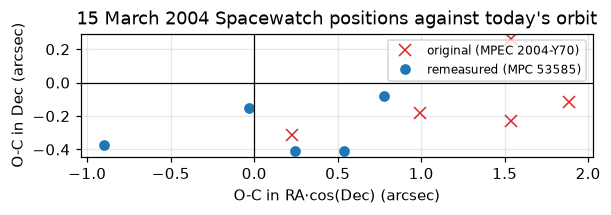

mean O-C, original  : RA +1.24"  Dec -0.12"
mean O-C, remeasured: RA +0.13"  Dec -0.29"


In [4]:
today = pyroorb.fit_orbit(obs, designation="99942")
print(f"today's orbit: {today.n_observations()} optical obs + {len(obs.meta['radar'])} radar, rms {today.rms_residual():.3f}\"")

def oc(f, records):
    out = []
    for o in records:
        p = pyroorb.ephemeris(f, o["jd_utc"], o["jd_utc"], site=o["obscode"], full=False)[0]
        out.append(((o["ra_deg"] - p["ra_deg"]) * 3600 * np.cos(np.radians(o["dec_deg"])),
                    (o["dec_deg"] - p["dec_deg"]) * 3600))
    return np.array(out)

o_orig, o_new = oc(today, original), oc(today, remeasured)
fig, ax = plt.subplots(figsize=(6, 4.5))
ax.plot(o_orig[:, 0], o_orig[:, 1], "x", ms=8, color="C3", label="original (MPEC 2004-Y70)")
ax.plot(o_new[:, 0], o_new[:, 1], "o", ms=6, color="C0", label="remeasured (MPC 53585)")
ax.axhline(0, color="k", lw=0.8); ax.axvline(0, color="k", lw=0.8)
ax.set(xlabel="O-C in RA·cos(Dec) (arcsec)", ylabel="O-C in Dec (arcsec)",
       title="15 March 2004 Spacewatch positions against today's orbit")
ax.set_aspect("equal"); ax.legend(fontsize=8); plt.show()
print(f"mean O-C, original  : RA {o_orig[:, 0].mean():+.2f}\"  Dec {o_orig[:, 1].mean():+.2f}\"")
print(f"mean O-C, remeasured: RA {o_new[:, 0].mean():+.2f}\"  Dec {o_new[:, 1].mean():+.2f}\"")

## Takeaways

* Five positions, about 1" apart in two reductions of the same images, change a 25-year prediction
  by tens of thousands of km. Against today's orbit the originals sit 1.2" east, the remeasured
  positions 0.1". At the end of an arc, a *systematic* error is not averaged down by the
  other 300 observations; it steers them.
* The radar did not just add precision; it was the independent measurement that exposed the bias.
  Remeasuring the images, not re-weighting them, was the fix.
* The second campaign cannot be replayed here: the MPC serves only the 2009 re-reductions of the
  June 2004 Kitt Peak nights (reference MPS 298141); the 2004 reductions survive in the
  literature as before-and-after impact probabilities.

**Caveats.** The 2004-only fits are gravity plus the 16 perturbers, with no Yarkovsky term (the
arc cannot determine one); their covariances are formal, and notebook 04 shows why the formal σ
can be optimistic. The MPEC lines carry no star-catalogue code, so they receive no debias
correction, while the remeasured lines (USNO-B1.0) do, a few hundredths of an arcsecond.